In [1]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Convert_Bispectrum/')

import os
import h5py
import numpy as np
import pandas as pd
import Visual_Helpers as VH
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d as inter
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

cmap = plt.get_cmap("tab10")

In [2]:
b1 = 9.8
b2 = 42.5

In [3]:
power_dir = '/home/kboone/software/Galaxy_Bias/Bispectrum/Two_Points_Data/'
model_power_file = power_dir + 'CLASS_power_z1' # Location of power spectrum file
k_model_orig, Pk_model_orig = VH.read_power(model_power_file)
max_k_model = np.max(k_model_orig)
Pk_model_orig = Pk_model_orig * (0.2322)**2 # Normalization to z=8

P = spline(k_model_orig, Pk_model_orig, bc_type='natural')

In [4]:
def get_P(directory = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'):
    phases = 25
    Pk = []
    for ph in np.arange(phases):
        power_file = directory + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
        
        df = pd.read_csv(power_file, sep=r'\s+')
        
        # Shift the header row to the left
        df.columns = np.roll(df.columns, -1)
        
        # Drop the first column (which now contains the original header)
        df = df.drop(df.columns[-1], axis=1)
        k = df['k_mean_over_bin_[h_Mpc^-1]'].to_numpy()
        N = df['N_modes'].to_numpy()
        Pk.append(df['P_bin_[h^-3_Mpc^3]'].to_numpy())
        
    Pk = np.array(Pk)
    return k, N, Pk


def data_bispec(bs_file, min_k, max_k, min_ksum, max_ksum):
    # This is for not doing any rounding, leads to ~10 times more points to compute
    # This is necessary in comparing to computed data though.
    df = pd.read_csv(bs_file, sep=r'\s+')
    
    # Shift the header row to the left
    df.columns = np.roll(df.columns, -1)
    
    # Drop the first column (which now contains the original header)
    df = df.drop(df.columns[-1], axis=1)
    
    B=np.array(df['B_bin_[h^-6_Mpc^6]'])
    N=np.array(df['N_modes'])
    k1=np.array(df['k1_mean_[h_Mpc^-1]'])
    k2=np.array(df['k2_mean_[h_Mpc^-1]'])
    k3=np.array(df['k3_mean_[h_Mpc^-1]'])
    
    ksum = k1+k2+k3
    cropInds = np.where((ksum >= min_ksum) & (ksum <= max_ksum) & 
                        (k1 >= min_k) & (k1 <= max_k) & 
                        (k2 >= min_k) & (k2 <= max_k) & 
                        (k3 >= min_k) & (k3 <= max_k))[0]

    B = B[cropInds]
    N = N[cropInds]
    k1 = k1[cropInds]
    k2 = k2[cropInds]
    k3 = k3[cropInds]
    ksum = ksum[cropInds]

    sortInds = np.argsort(ksum)
        
    B = B[sortInds]
    N = N[sortInds]
    k1 = k1[sortInds]
    k2 = k2[sortInds]
    k3 = k3[sortInds]
    
    ineqCrop = np.where((k1 >= k2) & (k2 >= k3))[0]
    
    B = B[ineqCrop]
    N = N[ineqCrop]
    k1 = k1[ineqCrop]
    k2 = k2[ineqCrop]
    k3 = k3[ineqCrop]
    
    BCrop = np.where(np.abs(B) < 1e12)[0] # Removes numerical issues
    
    B = B[BCrop]
    N = N[BCrop]
    k1 = k1[BCrop]
    k2 = k2[BCrop]
    k3 = k3[BCrop]

    return B, N, np.array([k1, k2, k3]).T

In [5]:
phases = 25
data_dir = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
z = 8
rescale = (8+1)/(z+1)

L = 2000
V = L**3
N_grid = 256
kF = 2*np.pi/L
kN = N_grid*np.pi/L

In [6]:
pos_root = '../../Data/Gala_z8_Positions/'

noises = np.zeros(phases, dtype=np.float64)

for ph in np.arange(phases):
    pos_file = pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5'
    
    with h5py.File(pos_file, 'r') as f_:
        dset = f_['dataset']
        pos = dset[:].T
        noises[ph] = V/len(pos)

ave_noise = V / np.average(V / noises)

In [7]:
k, Nk, Pk = get_P(directory = data_dir)
# Pk = (Pk.T - noises).T
std_P = np.std(Pk, axis=0, ddof=1)
std_cov = np.outer(std_P, std_P)
cov_P = np.cov(Pk.T, ddof=1)
kMax_P = kN

In [8]:
max_ksum = kN
min_ksum = max_ksum/4

min_k = 0.5*kF
max_k = 64.5*kF
Bs = []

for ph in np.arange(phases):
    bs_file = data_dir + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_comb.dat'
    B, N123, kB = data_bispec(bs_file, min_k, max_k, min_ksum, max_ksum)
    Bs.append(B)

Bs = np.array(Bs)
k1, k2, k3 = kB[:,0], kB[:,1], kB[:,2]

In [9]:
k_round = np.round((k/kF+0.5)/2).astype(int)
k1_round = np.round((k1/kF+0.5)/2).astype(int)
k2_round = np.round((k2/kF+0.5)/2).astype(int)
k3_round = np.round((k3/kF+0.5)/2).astype(int)

In [10]:
k_over_Nk_k1 = ((k/Nk)[:, None] / k1[None, :])
k_over_Nk_k2 = ((k/Nk)[:, None] / k2[None, :])
k_over_Nk_k3 = ((k/Nk)[:, None] / k3[None, :])

deltakk1 = (k_round[:, None] == k1_round[None, :]).astype(int)
deltakk2 = (k_round[:, None] == k2_round[None, :]).astype(int)
deltakk3 = (k_round[:, None] == k3_round[None, :]).astype(int)

P_k = P(k)[:, None]
P_k1 = P(k1)[None, :]
P_k2 = P(k2)[None, :]
P_k3 = P(k3)[None, :]

In [11]:
# Factor of 2, comes from the 4 times a one half.
cross_cov = 2*b1**4*b2*(deltakk1 * k_over_Nk_k1 * (P_k*P_k2*P_k3 + P_k**2*(P_k2+P_k3)) + 
                        deltakk2 * k_over_Nk_k2 * (P_k*P_k1*P_k3 + P_k**2*(P_k1+P_k3)) +
                        deltakk3 * k_over_Nk_k3 * (P_k*P_k1*P_k2 + P_k**2*(P_k1+P_k2)))

dat_cross = np.cov(Pk.T, Bs.T)[:Pk.shape[1],Pk.shape[1]:]

In [12]:
np.save('Cross_Cov.npy', cross_cov)

In [13]:
def N123_pred(k1, k2, k3):
    dk = 2*kF
    delta = (k1**2-k2**2-k3**2)/(2*k2*k3)
    b = 1
    if np.abs(delta) > 0.9:
        b = 0.5
    return 8 * np.pi**2 * k1 * k2 * k3 * dk**3 * b / kF**6

pred_N = []
for i in np.arange(len(k1)):
    pred_N.append(N123_pred(k1[i], k2[i], k3[i]))
pred_N = np.array(pred_N)

off_inds = np.where(N123/pred_N < 0.2)[0]

# This means in the squeezed limit the actual number of modes is far fewer than predicted
np.min(k1[off_inds] / (k2[off_inds] + k3[off_inds]))

np.float64(0.9909755732810099)

In [14]:
test = np.zeros(Bs.shape[1])
test[off_inds] = 1 # These are really the inds where I'm disagreeing.

test_arr = np.ones(Pk.shape[1])[:, None] * test[None, :]

In [15]:
max_cross = np.max(np.abs(cross_cov))

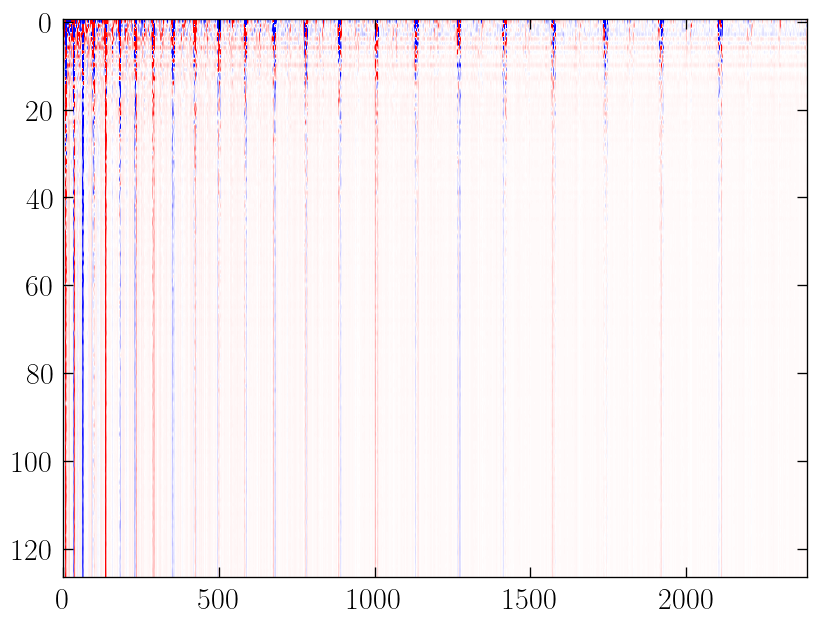

In [16]:
plt.figure(dpi = 120)
plt.imshow(dat_cross/max_cross, aspect='auto', vmin=-1, vmax=1, cmap='bwr')
plt.show()

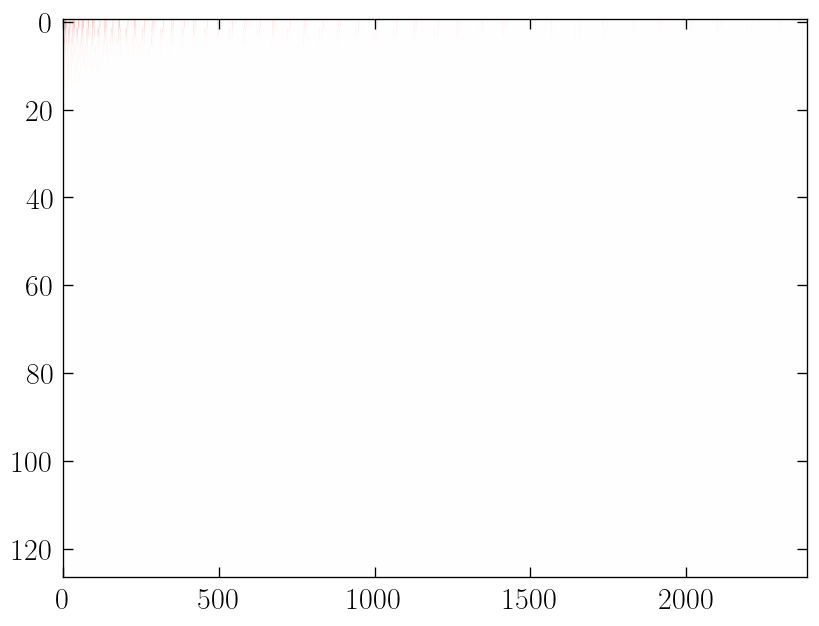

In [17]:
plt.figure(dpi = 120)
plt.imshow(cross_cov/max_cross, aspect='auto', vmin=-1, vmax=1, cmap='bwr')
plt.show()